# 📉 02 · The Unthresholded Perceptron and the Delta Rule

> **Module 01 – Perceptron and Gradient Descent** · Notebook 2 of 3
> Course notes: *Unthresholded perceptron, cost function, gradient of cost function* (pages 2–3) · Mitchell, *Machine Learning* §4.4

Notebook 01 ended with two problems: a perceptron can only draw one line, and its **step function has zero slope**, so we can't use calculus to train it. Here we fix the second problem with one small change: **throw the step away.** The output becomes a real number, we can measure *how* wrong it is, and we can **roll downhill on the error** – this is **gradient descent**, the engine behind every model in this repository.

### 🎯 What you will learn

| # | Idea | Formula |
|---|---|---|
| 1 | The linear (unthresholded) unit | $o(\vec x)=\vec w\cdot\vec x$ |
| 2 | One number for "how bad": the cost function | $E(\vec w)=\tfrac12\sum_{d\in D}(t_d-o_d)^2$ |
| 3 | The gradient: which way is uphill? | $\nabla E=\big[\tfrac{\partial E}{\partial w_0},\dots,\tfrac{\partial E}{\partial w_n}\big]$ |
| 4 | Gradient descent / the **delta rule** | $\Delta w_i=\eta\sum_d(t_d-o_d)\ x_{i,d}$ |
| 5 | Batch vs stochastic (incremental) gradient descent | update after all data vs after each example |
| 6 | Choosing the learning rate $\eta$ | too small = slow, too big = explodes |

## 0 · Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

# ---------- one consistent, clean plotting style for the whole notebook ----------
C = dict(blue="#2a78d6", orange="#eb6834", aqua="#1baf7a", yellow="#eda100",
         magenta="#e87ba4", green="#008300", violet="#6250d6", red="#e34948",
         ink="#0b0b0b", muted="#52514e", grid="#e6e5e1")
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": C["muted"], "axes.labelcolor": C["ink"], "axes.titleweight": "bold",
    "axes.titlesize": 12, "axes.labelsize": 10.5, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": C["grid"], "grid.linewidth": 0.8,
    "xtick.color": C["muted"], "ytick.color": C["muted"], "legend.frameon": False,
    "lines.linewidth": 2.0, "font.size": 10.5,
    "axes.prop_cycle": plt.cycler(color=[C[k] for k in
                       ["blue", "orange", "aqua", "yellow", "magenta", "green", "violet", "red"]]),
})
REGION_CMAP = ListedColormap(["#d6e6f8", "#fcdccd"])
POINT_CMAP  = ListedColormap([C["blue"], C["orange"]])
np.set_printoptions(precision=4, suppress=True)

---
## 1 · The variables 📖

| Symbol | Meaning | Example |
|---|---|---|
| $D$ | the training set; $d$ indexes one example in it | 3 examples |
| $\vec x_d=(x_{0,d},x_{1,d},\dots,x_{n,d})$ | input vector of example $d$, with $x_{0,d}=1$ (bias) | $(1,\ 2)$ |
| $x_{i,d}$ | input $i$ of example $d$ | $x_{1,2}=2$ |
| $t_d$ | **target** (true value) of example $d$ | $6$ |
| $\vec w=(w_0,\dots,w_n)$ | the weights we are learning | $(-2,\ 4)$ |
| $o_d=\vec w\cdot\vec x_d$ | **output** of the linear unit for example $d$ (a real number now!) | $5.7$ |
| $t_d-o_d$ | **error** on example $d$ (signed) | $0.3$ |
| $E(\vec w)$ | **cost**: one number summarising all errors | – |
| $\nabla E$ | **gradient**: vector of slopes of $E$, one per weight | – |
| $\eta$ | **learning rate**, the step size | $0.02$ |

---
## 2 · Remove the threshold ✂️

$$\textbf{thresholded: } o=\text{sgn}(\vec w\cdot\vec x)\in\lbrace -1,+1\rbrace \qquad\Longrightarrow\qquad \textbf{unthresholded: } \boxed{o(\vec x)=\vec w\cdot\vec x}\in\mathbb R$$

Why does that help? Look at how the output reacts to a tiny change in $net$:

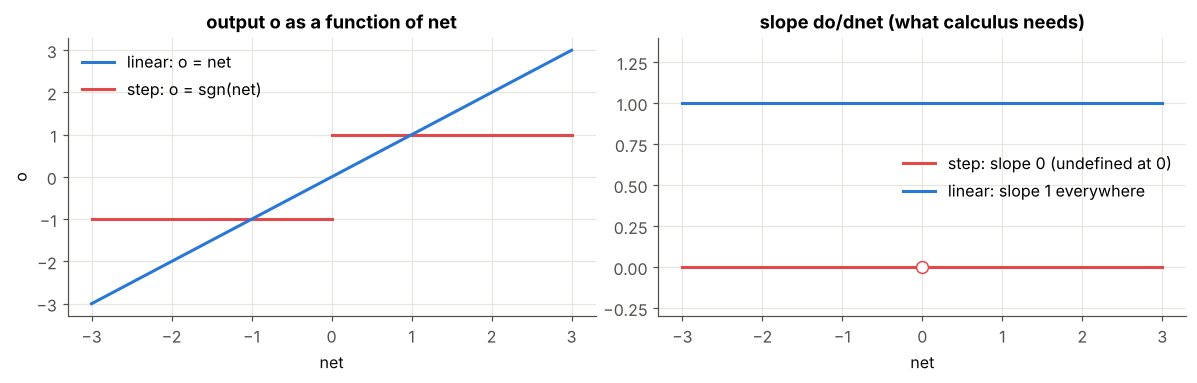

In [2]:
net = np.linspace(-3, 3, 601)
step = np.where(net > 0, 1.0, -1.0)

fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
axs[0].plot(net[net <= 0], step[net <= 0], color=C["red"]); axs[0].plot(net[net > 0], step[net > 0], color=C["red"])
axs[0].plot(net, net, color=C["blue"], label="linear: o = net")
axs[0].plot([], [], color=C["red"], label="step: o = sgn(net)")
axs[0].set_title("output o as a function of net"); axs[0].set_xlabel("net"); axs[0].set_ylabel("o"); axs[0].legend()

axs[1].plot(net, np.zeros_like(net), color=C["red"], label="step: slope 0 (undefined at 0)")
axs[1].plot(net, np.ones_like(net), color=C["blue"], label="linear: slope 1 everywhere")
axs[1].scatter([0], [0], s=60, facecolor="white", edgecolor=C["red"], zorder=3)
axs[1].set_ylim(-0.3, 1.4); axs[1].set_title("slope do/dnet (what calculus needs)")
axs[1].set_xlabel("net"); axs[1].legend(loc="center right")
plt.tight_layout(); plt.show()

**Intuition.** With the step, being "a bit wrong" and "very wrong" look identical, and nudging a weight changes nothing until the output suddenly flips. With the linear unit, an output of 5.7 against a target of 6 says *"you are 0.3 too low"* – and the slope tells us exactly how each weight affects that.

---
## 3 · One number for "how bad": the cost function 📏

From the course notes:

$$\boxed{E(\vec w)=\frac12\sum_{d\in D}\big(t_d-o_d\big)^2}$$

* **Why square?** Positive and negative errors can't cancel, and big errors are punished much more than small ones.
* **Why $\tfrac12$?** Pure convenience: when we differentiate $(\cdot)^2$ a factor 2 appears and cancels it.
* **Key point:** the data $D$ is fixed, so $E$ is a function of **the weights only**. Learning = finding the $\vec w$ where $E$ is smallest.

### Our running example (from the notes)
The notes list the data $x = 1, 2, 3 \ \to\  y = 2, 6, 10$ and remark that the thresholded perceptron *"won't work"* (it can only say ±1). A linear unit can: the data lie exactly on $y = 4x - 2$, so the perfect weights are $w_0=-2,\ w_1=4$ with $E=0$.

In [3]:
x_notes = np.array([1.0, 2.0, 3.0])
t_notes = np.array([2.0, 6.0, 10.0])
X_notes = np.c_[np.ones(3), x_notes]               # add the bias input x0 = 1 → rows (1, x)

def cost(w, X, t):
    """E(w) = 1/2 * sum_d (t_d - o_d)^2   with   o_d = w · x_d"""
    o = X @ w                                      # outputs for all examples at once
    return 0.5 * np.sum((t - o) ** 2)

for w_try in [np.array([0.0, 0.0]), np.array([0.0, 3.0]), np.array([-2.0, 4.0])]:
    print(f"w = {w_try}:  outputs o = {X_notes @ w_try},  E(w) = {cost(w_try, X_notes, t_notes):.2f}")

w = [0. 0.]:  outputs o = [0. 0. 0.],  E(w) = 70.00
w = [0. 3.]:  outputs o = [3. 6. 9.],  E(w) = 1.00
w = [-2.  4.]:  outputs o = [ 2.  6. 10.],  E(w) = 0.00


Because $o$ is linear in $\vec w$ and $E$ squares it, **$E(\vec w)$ is a bowl** (a paraboloid) with a single lowest point. Let us draw it over the $(w_0, w_1)$ plane.

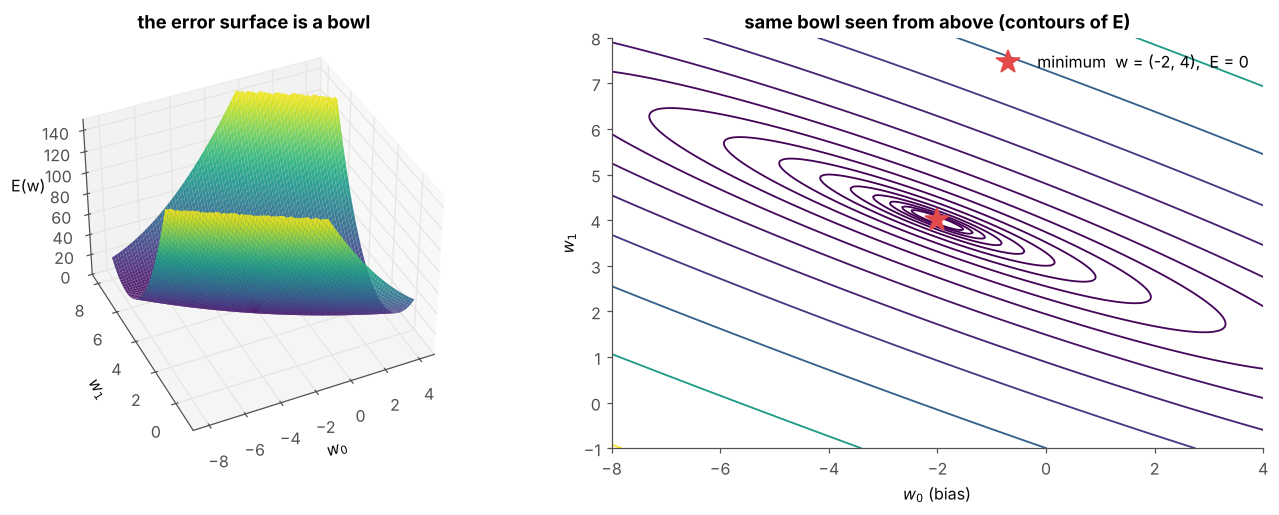

In [4]:
w0g, w1g = np.meshgrid(np.linspace(-8, 4, 241), np.linspace(-1, 8, 241))
# E for every (w0, w1) pair on the grid, computed with broadcasting
O = w0g[..., None] + w1g[..., None] * x_notes          # outputs, shape (241, 241, 3)
Egrid = 0.5 * np.sum((t_notes - O) ** 2, axis=-1)

fig = plt.figure(figsize=(12.5, 4.8))
ax3 = fig.add_subplot(1, 2, 1, projection="3d")
Eclip = np.where(Egrid < 150, Egrid, np.nan)                 # cut the walls so the bowl shape is visible
ax3.plot_surface(w0g, w1g, Eclip, cmap="viridis", linewidth=0, alpha=0.92, rstride=3, cstride=3, vmax=150)
ax3.scatter([-2], [4], [0], color=C["red"], s=50)
ax3.set_xlabel("$w_0$"); ax3.set_ylabel("$w_1$"); ax3.set_zlabel("E(w)"); ax3.set_zlim(0, 150)
ax3.set_title("the error surface is a bowl"); ax3.view_init(38, -115)

ax = fig.add_subplot(1, 2, 2)
cs = ax.contour(w0g, w1g, Egrid, levels=np.geomspace(0.05, 400, 16), cmap="viridis", linewidths=1.2)
ax.plot(-2, 4, "*", color=C["red"], ms=16, label="minimum  w = (-2, 4),  E = 0")
ax.set_xlabel("$w_0$ (bias)"); ax.set_ylabel("$w_1$"); ax.set_title("same bowl seen from above (contours of E)")
ax.legend(loc="upper right"); ax.grid(False)
plt.tight_layout(); plt.show()

The contours are long, thin ellipses: the bowl is **steep in one direction and nearly flat in another**. Remember this – it will explain the zig-zag path of gradient descent below.

---
## 4 · Which way is downhill? The gradient 🧭

Imagine standing on the bowl in thick fog. You can't see the bottom, but you can feel the slope under your feet. The **gradient** collects the slope in every weight direction:

$$\nabla E(\vec w)=\left[\frac{\partial E}{\partial w_0},\ \frac{\partial E}{\partial w_1},\ \dots,\ \frac{\partial E}{\partial w_n}\right]$$

It points **uphill** (steepest increase). So we step the **opposite** way:

$$\boxed{\vec w\leftarrow\vec w+\Delta\vec w,\qquad \Delta\vec w=-\eta\ \nabla E(\vec w)}$$

### Deriving $\partial E/\partial w_i$ step by step

$$\begin{aligned} \frac{\partial E}{\partial w_i} &=\frac{\partial}{\partial w_i}\ \frac12\sum_{d}(t_d-o_d)^2 &&\text{definition of }E\cr &=\frac12\sum_d 2\ (t_d-o_d)\ \frac{\partial}{\partial w_i}(t_d-o_d) &&\text{chain rule; the }\tfrac12\text{ cancels the }2\cr &=\sum_d (t_d-o_d)\ \frac{\partial}{\partial w_i}\big(t_d-\vec w\cdot\vec x_d\big) &&o_d=\vec w\cdot\vec x_d\cr &=\sum_d (t_d-o_d)\ (-x_{i,d}) &&t_d\text{ does not depend on }w_i;\ \tfrac{\partial}{\partial w_i}(\vec w\cdot\vec x_d)=x_{i,d} \end{aligned}$$

$$\boxed{\frac{\partial E}{\partial w_i}=-\sum_{d\in D}(t_d-o_d)\ x_{i,d}} \qquad\Longrightarrow\qquad \boxed{\Delta w_i=-\eta\frac{\partial E}{\partial w_i}=\eta\sum_{d\in D}(t_d-o_d)\ x_{i,d}}$$

This is the **delta rule** (also called the LMS or Widrow–Hoff rule). Compare it with the perceptron rule $\Delta w_i=\eta(t-o)x_i$ – same shape! The difference is that $o$ is now a real number, so $(t-o)$ measures **how much** we are wrong, not just whether.

In matrix form for all weights at once (rows of $X$ are examples): $\nabla E = -X^\top(\vec t-\vec o)$.

### ✅ Check the formula against a "brute force" slope
A derivative is the slope of a tiny step: $\frac{\partial E}{\partial w_i}\approx\frac{E(w_i+\varepsilon)-E(w_i-\varepsilon)}{2\varepsilon}$. If our algebra is right, both must agree.

In [5]:
def gradient(w, X, t):
    """∇E = - sum_d (t_d - o_d) x_d   (one entry per weight)   = -X^T (t - o)"""
    return -X.T @ (t - X @ w)

def numerical_gradient(w, X, t, eps=1e-6):
    g = np.zeros_like(w)
    for i in range(len(w)):
        e = np.zeros_like(w); e[i] = eps
        g[i] = (cost(w + e, X, t) - cost(w - e, X, t)) / (2 * eps)   # central difference
    return g

w_test = np.array([0.5, 1.5])
print("analytic  ∇E :", gradient(w_test, X_notes, t_notes))
print("numerical ∇E :", numerical_gradient(w_test, X_notes, t_notes))
print("match?       :", np.allclose(gradient(w_test, X_notes, t_notes), numerical_gradient(w_test, X_notes, t_notes)))

analytic  ∇E : [ -7.5 -20. ]
numerical ∇E : [ -7.5 -20. ]
match?       : True


Both entries are negative → increasing $w_0$ and $w_1$ lowers the error, so gradient descent will increase them. That makes sense: $\vec w=(0.5,1.5)$ predicts outputs that are too small.

---
## 5 · Implementation: batch and stochastic gradient descent 💻

There are two ways to use the delta rule:

| | **Batch** gradient descent | **Stochastic / incremental** gradient descent |
|---|---|---|
| Update after | **all** examples (sum over $D$) | **each** example |
| Update | $\Delta w_i=\eta\sum_d(t_d-o_d)x_{i,d}$ | $\Delta w_i=\eta(t_d-o_d)x_{i,d}$ |
| Follows | the true gradient of $E$ | a noisy estimate of it |
| Cost per update | high (one pass over the data) | tiny |
| Path | smooth | jittery, but often reaches a good region faster |

In [6]:
class LinearUnit:
    """Unthresholded perceptron  o = w·x,  trained with the delta rule (gradient descent on E)."""

    def __init__(self, learning_rate=0.01, epochs=50, mode="batch", seed=0):
        self.eta = learning_rate      # η : step size
        self.epochs = epochs          # passes over the data
        self.mode = mode              # "batch" or "stochastic"
        self.rng = np.random.default_rng(seed)

    @staticmethod
    def add_bias(X):
        return np.c_[np.ones((X.shape[0], 1)), X]          # x0 = 1 for every example

    def cost(self, Xb, t):
        return 0.5 * np.sum((t - Xb @ self.w) ** 2)       # E(w) = 1/2 Σ (t_d - o_d)^2

    def fit(self, X, t, w_init=None):
        Xb = self.add_bias(X)
        self.w = np.zeros(Xb.shape[1]) if w_init is None else np.array(w_init, float)
        self.cost_history = [self.cost(Xb, t)]             # E before any training
        self.w_history = [self.w.copy()]
        for epoch in range(self.epochs):
            if self.mode == "batch":
                o = Xb @ self.w                            # outputs for ALL examples
                grad = -Xb.T @ (t - o)                     # ∂E/∂w_i = -Σ_d (t_d - o_d) x_id
                self.w = self.w - self.eta * grad          # one step downhill
                self.w_history.append(self.w.copy())
            else:  # stochastic: one small step per example, in random order
                for d in self.rng.permutation(len(t)):
                    o_d = Xb[d] @ self.w                   # output for example d only
                    self.w = self.w + self.eta * (t[d] - o_d) * Xb[d]   # Δw = η (t_d - o_d) x_d
                    self.w_history.append(self.w.copy())
            self.cost_history.append(self.cost(Xb, t))     # E after this epoch
        self.w_history = np.array(self.w_history)
        return self

    def predict(self, X):
        return self.add_bias(X) @ self.w

### 🔍 Walk-through
* `grad = -Xb.T @ (t - o)` is the boxed formula for all weights at once: row $i$ of `Xb.T` holds $x_{i,d}$ for every $d$, so the matrix product computes $\sum_d (t_d-o_d)x_{i,d}$.
* Batch mode makes **one** update per epoch. Stochastic mode makes **one per example**, visiting them in a fresh random order each epoch (`rng.permutation`).
* We store `w_history` so we can draw the path the weights take across the bowl.

---
## 6 · Watch it learn on the notes' data, step by step 👣

In [7]:
gd = LinearUnit(learning_rate=0.02, epochs=1).fit(x_notes[:, None], t_notes)
Xb = gd.add_bias(x_notes[:, None])
w = np.zeros(2)
print("start: w =", w, " E =", cost(w, Xb, t_notes))
for step in range(1, 4):
    o = Xb @ w
    err = t_notes - o
    grad = -Xb.T @ err
    w = w - 0.02 * grad
    print(f"step {step}: o = {o}, t - o = {err}, ∇E = {grad}, new w = {w}, E = {cost(w, Xb, t_notes):.3f}")

start: w = [0. 0.]  E = 70.0
step 1: o = [0. 0. 0.], t - o = [ 2.  6. 10.], ∇E = [-18. -44.], new w = [0.36 0.88], E = 32.316
step 2: o = [1.24 2.12 3.  ], t - o = [0.76 3.88 7.  ], ∇E = [-11.64 -29.52], new w = [0.5928 1.4704], E = 15.524
step 3: o = [2.0632 3.5336 5.004 ], t - o = [-0.0632  2.4664  4.996 ], ∇E = [ -7.3992 -19.8576], new w = [0.7408 1.8676], E = 8.032


Check step 1 by hand: $o=(0,0,0)$, errors $=(2,6,10)$.
$\partial E/\partial w_0=-(2+6+10)=-18$ and $\partial E/\partial w_1=-(2\cdot1+6\cdot2+10\cdot3)=-44$.
With $\eta=0.02$: $\Delta\vec w=(0.36,\ 0.88)$. ✅

Now run it for many epochs and draw the **path across the bowl**, for both modes.

In [8]:
batch = LinearUnit(learning_rate=0.02, epochs=1500, mode="batch").fit(x_notes[:, None], t_notes)
sgd   = LinearUnit(learning_rate=0.02, epochs=500, mode="stochastic").fit(x_notes[:, None], t_notes)
print(f"batch GD      → w = {batch.w}   E = {batch.cost_history[-1]:.2e}")
print(f"stochastic GD → w = {sgd.w}   E = {sgd.cost_history[-1]:.2e}   (constant η keeps it jittering near the minimum)")
print("exact answer  → w = [-2.  4.]")

batch GD      → w = [-1.9999  4.    ]   E = 7.93e-10
stochastic GD → w = [-1.9261  3.968 ]   E = 1.17e-03   (constant η keeps it jittering near the minimum)
exact answer  → w = [-2.  4.]


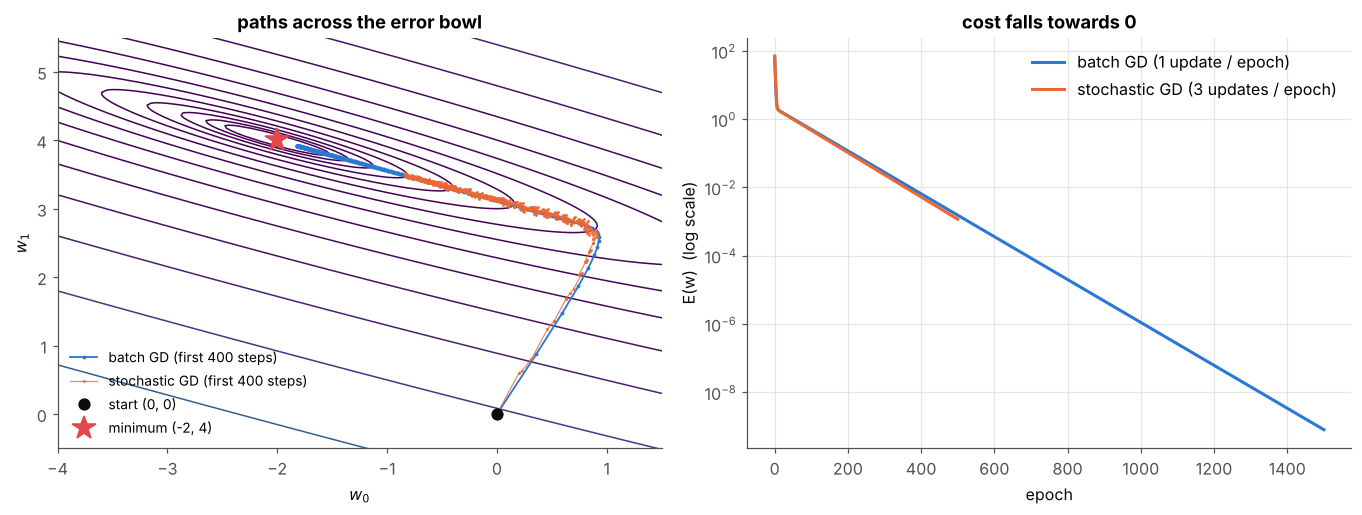

In [9]:
fig, axs = plt.subplots(1, 2, figsize=(12.5, 4.8))
ax = axs[0]
ax.contour(w0g, w1g, Egrid, levels=np.geomspace(0.05, 400, 16), cmap="viridis", linewidths=1)
ax.plot(*batch.w_history[:400].T, ".-", color=C["blue"], ms=3, lw=1.2, label="batch GD (first 400 steps)")
ax.plot(*sgd.w_history[:400].T, ".-", color=C["orange"], ms=2, lw=0.8, alpha=0.8, label="stochastic GD (first 400 steps)")
ax.plot(0, 0, "o", color=C["ink"], ms=7, label="start (0, 0)")
ax.plot(-2, 4, "*", color=C["red"], ms=16, label="minimum (-2, 4)")
ax.set_xlim(-4, 1.5); ax.set_ylim(-0.5, 5.5); ax.grid(False)
ax.set_xlabel("$w_0$"); ax.set_ylabel("$w_1$"); ax.set_title("paths across the error bowl"); ax.legend(loc="lower left", fontsize=9)

ax = axs[1]
ax.semilogy(batch.cost_history, color=C["blue"], label="batch GD (1 update / epoch)")
ax.semilogy(np.arange(len(sgd.cost_history)) , sgd.cost_history, color=C["orange"], label="stochastic GD (3 updates / epoch)")
ax.set_xlabel("epoch"); ax.set_ylabel("E(w)  (log scale)"); ax.set_title("cost falls towards 0"); ax.legend()
plt.tight_layout(); plt.show()

**What you see:**
1. Both paths first rush down the **steep** wall of the bowl, then crawl along the **flat valley floor** towards $(-2,4)$. The steep direction is learned in a few steps; the flat direction takes hundreds.
2. The straight-line fit through the data improves at every stage:

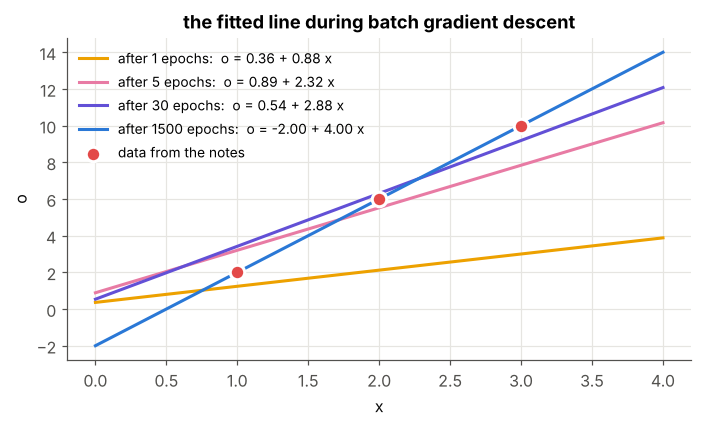

In [10]:
fig, ax = plt.subplots(figsize=(6.5, 4))
xs = np.linspace(0, 4, 50)
for k, col in zip([1, 5, 30, 1500], [C["yellow"], C["magenta"], C["violet"], C["blue"]]):
    wk = batch.w_history[k]
    ax.plot(xs, wk[0] + wk[1] * xs, color=col, label=f"after {k} epochs:  o = {wk[0]:.2f} + {wk[1]:.2f} x")
ax.scatter(x_notes, t_notes, s=90, color=C["red"], zorder=3, edgecolor="white", linewidth=2, label="data from the notes")
ax.set_xlabel("x"); ax.set_ylabel("o"); ax.set_title("the fitted line during batch gradient descent"); ax.legend(fontsize=9)
plt.tight_layout(); plt.show()

---
## 7 · The learning rate $\eta$: the most important knob 🎚️

$\eta$ controls the step length. For this bowl, any $\eta$ above about $0.12$ makes the steps **overshoot** across the valley and grow – the cost explodes.

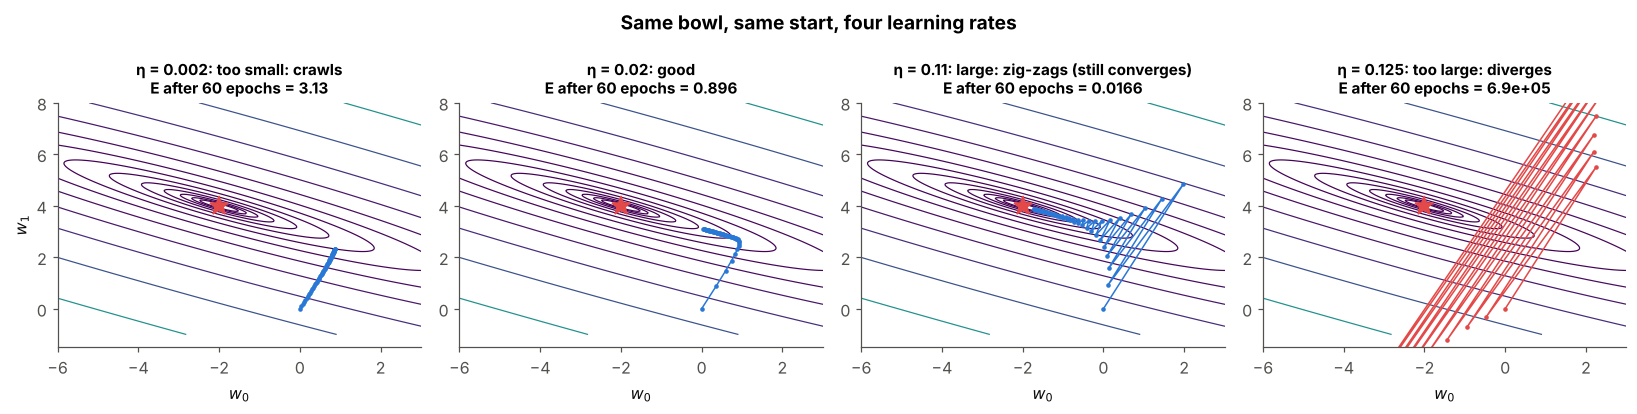

In [11]:
etas = {0.002: "too small: crawls", 0.02: "good", 0.11: "large: zig-zags (still converges)", 0.125: "too large: diverges"}
fig, axs = plt.subplots(1, 4, figsize=(15, 3.8))
for ax, (eta, label) in zip(axs, etas.items()):
    m = LinearUnit(learning_rate=eta, epochs=60, mode="batch").fit(x_notes[:, None], t_notes)
    ax.contour(w0g, w1g, Egrid, levels=np.geomspace(0.05, 400, 14), cmap="viridis", linewidths=0.8)
    path = m.w_history[:18] if "diverges" in label else m.w_history   # diverging path: first steps only
    ax.plot(*path.T, ".-", color=C["red"] if "diverges" in label else C["blue"], ms=4, lw=1)
    ax.plot(-2, 4, "*", color=C["red"], ms=13)
    ax.set_xlim(-6, 3); ax.set_ylim(-1.5, 8); ax.grid(False)
    ax.set_title(f"η = {eta}: {label}\nE after 60 epochs = {m.cost_history[-1]:.3g}", fontsize=10)
    ax.set_xlabel("$w_0$")
axs[0].set_ylabel("$w_1$")
fig.suptitle("Same bowl, same start, four learning rates", fontweight="bold")
plt.tight_layout(); plt.show()

> 💡 **Rule of thumb:** start with a small $\eta$, increase it by ×3 until the cost stops falling smoothly, then back off. (Why exactly 0.12 here? The curvature of the bowl in its steepest direction is the largest eigenvalue $\lambda_{max}$ of $X^\top X\approx16.7$; plain gradient descent is stable only if $\eta<2/\lambda_{max}\approx0.12$.)

---
## 8 · Batch vs stochastic on a bigger, noisy dataset 🎲

Now 100 noisy points around $y=3x+5$. With many examples, stochastic GD gets **100 updates per epoch** instead of 1.

In [12]:
rng = np.random.default_rng(42)
X_data = np.linspace(0, 10, 100).reshape(-1, 1)
t_data = 3 * X_data.ravel() + 5 + rng.normal(0, 2, 100)

batch_n = LinearUnit(learning_rate=4e-4, epochs=100, mode="batch").fit(X_data, t_data)
sgd_n   = LinearUnit(learning_rate=2e-3, epochs=100, mode="stochastic").fit(X_data, t_data)
w_exact = np.linalg.lstsq(np.c_[np.ones(100), X_data], t_data, rcond=None)[0]   # best possible weights
print(f"batch GD      w = {batch_n.w}   E = {batch_n.cost_history[-1]:8.1f}")
print(f"stochastic GD w = {sgd_n.w}   E = {sgd_n.cost_history[-1]:8.1f}")
print(f"least squares w = {w_exact}   E = {0.5 * np.sum((t_data - np.c_[np.ones(100), X_data] @ w_exact) ** 2):8.1f}  (the true minimum)")

batch GD      w = [3.5593 3.1807]   E =    155.7
stochastic GD w = [5.2835 2.8833]   E =    118.9
least squares w = [5.319  2.9161]   E =    116.4  (the true minimum)


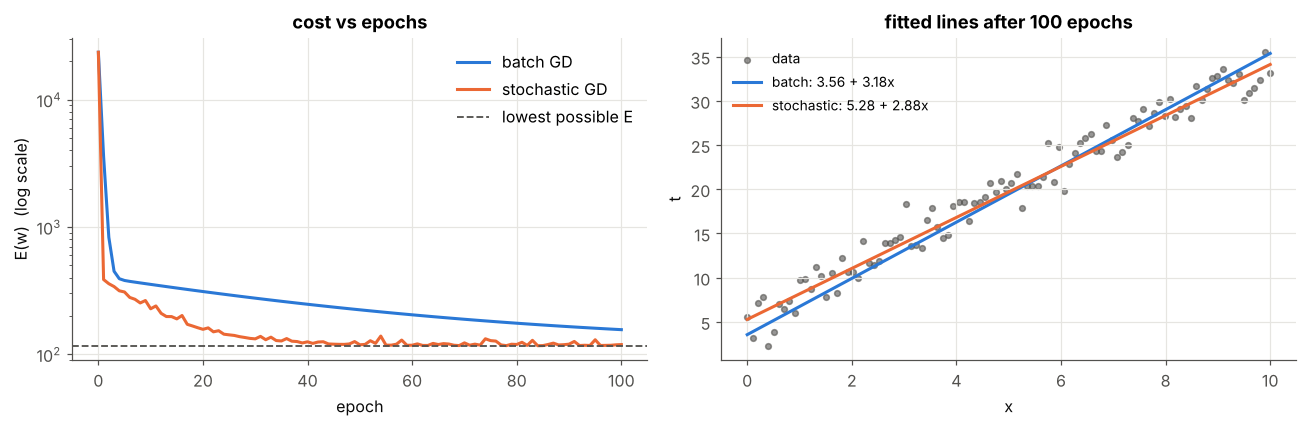

In [13]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
axs[0].semilogy(batch_n.cost_history, color=C["blue"], label="batch GD")
axs[0].semilogy(sgd_n.cost_history, color=C["orange"], label="stochastic GD")
axs[0].axhline(0.5 * np.sum((t_data - np.c_[np.ones(100), X_data] @ w_exact) ** 2), color=C["muted"], ls="--", lw=1.2, label="lowest possible E")
axs[0].set_title("cost vs epochs"); axs[0].set_xlabel("epoch"); axs[0].set_ylabel("E(w)  (log scale)"); axs[0].legend()

axs[1].scatter(X_data, t_data, s=14, color=C["muted"], alpha=0.6, label="data")
xs = np.linspace(0, 10, 2)
axs[1].plot(xs, batch_n.w[0] + batch_n.w[1] * xs, color=C["blue"], label=f"batch: {batch_n.w[0]:.2f} + {batch_n.w[1]:.2f}x")
axs[1].plot(xs, sgd_n.w[0] + sgd_n.w[1] * xs, color=C["orange"], label=f"stochastic: {sgd_n.w[0]:.2f} + {sgd_n.w[1]:.2f}x")
axs[1].set_title("fitted lines after 100 epochs"); axs[1].set_xlabel("x"); axs[1].set_ylabel("t"); axs[1].legend(fontsize=9)
plt.tight_layout(); plt.show()

**Reading the plots.** After 100 epochs, batch GD has the slope ($\approx 3$) right but its intercept is still crawling up from 0 (the flat valley again). Stochastic GD made 100× more updates and is already near the best line, but its cost **wiggles** because each step only listens to one example.

---
## 9 · The delta rule for classification (and XOR again) 🔁

We can also use the linear unit as a classifier: train it on ±1 targets with the delta rule, then apply the threshold **only when predicting**. Two big differences from the perceptron:
* It **always converges** (to the least-squares weights), even when the data are not separable – no endless cycling.
* But on XOR the best straight line is useless: the least-squares answer is $\vec w=\vec 0$.

AND: w = [-1.5  1.   1. ],  raw outputs o = [-1.5 -0.5 -0.5  0.5],  thresholded = [-1 -1 -1  1],  accuracy = 100%
XOR: w = [0. 0. 0.],  raw outputs o = [0. 0. 0. 0.],  thresholded = [-1 -1 -1 -1],  accuracy = 50%


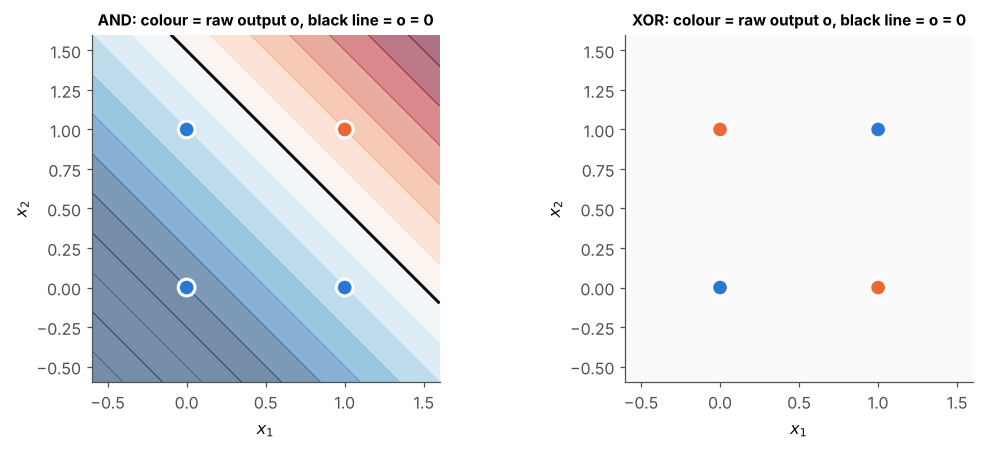

In [14]:
X_gate = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)
gate_targets = {"AND": np.array([-1, -1, -1, 1.0]), "XOR": np.array([-1, 1, 1, -1.0])}

fig, axs = plt.subplots(1, 2, figsize=(10, 4.2))
for ax, (name, tg) in zip(axs, gate_targets.items()):
    m = LinearUnit(learning_rate=0.05, epochs=500, mode="batch").fit(X_gate, tg)
    pred = np.where(m.predict(X_gate) > 0, 1, -1)
    print(f"{name}: w = {m.w + 0.0},  raw outputs o = {m.predict(X_gate) + 0.0},  "
          f"thresholded = {pred},  accuracy = {(pred == tg).mean():.0%}")
    g = np.linspace(-0.6, 1.6, 300); xx, yy = np.meshgrid(g, g)
    oo = m.w[0] + m.w[1] * xx + m.w[2] * yy
    ax.contourf(xx, yy, oo, levels=20, cmap="RdBu_r", alpha=0.55, vmin=-1.5, vmax=1.5)
    if np.abs(m.w[1:]).max() > 1e-6:
        ax.contour(xx, yy, oo, levels=[0], colors=C["ink"], linewidths=2)
    ax.scatter(X_gate[:, 0], X_gate[:, 1], c=(tg > 0).astype(int), cmap=POINT_CMAP, s=120, edgecolor="white", linewidth=2, zorder=3)
    ax.set_title(f"{name}: colour = raw output o, black line = o = 0", fontsize=10)
    ax.set_aspect("equal"); ax.grid(False); ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$")
plt.tight_layout(); plt.show()

For AND the line at $o=0$ separates the classes. For XOR every output is 0 – the "best" line sits nowhere. **A single linear unit still cannot do XOR.** We need *non-linear* units stacked in layers – that is notebook 03.

---
## 10 · Summary 📌

| Concept | Formula |
|---|---|
| Linear unit | $o=\vec w\cdot\vec x$ |
| Cost | $E(\vec w)=\tfrac12\sum_d(t_d-o_d)^2$ |
| Gradient | $\dfrac{\partial E}{\partial w_i}=-\sum_d(t_d-o_d)x_{i,d}$ |
| Batch delta rule | $\Delta w_i=\eta\sum_d(t_d-o_d)x_{i,d}$ |
| Stochastic delta rule | $\Delta w_i=\eta(t_d-o_d)x_{i,d}$, after every example |
| Stability | $\eta$ must be small enough ($\eta<2/\lambda_{max}$ for batch GD) |

**Perceptron rule vs delta rule:** same formula shape, but the perceptron uses the *thresholded* output (and stops only if the data are separable), while the delta rule uses the *raw* output (and always converges to the least-squares fit).

**Still missing:** a network of linear units is no better than one linear unit (notes: *"network of linear neurons will have same effect as a single neuron"*). We need non-linearity → **sigmoid**.

### ✍️ Try it yourself
1. Find the largest $\eta$ that still converges on the notes' data. Compare with $2/\lambda_{max}$ from `np.linalg.eigvalsh(Xb.T @ Xb)`.
2. Standardise $x$ (subtract the mean, divide by the std) before training on the noisy data. Why does batch GD suddenly converge in a few epochs? *(Hint: the bowl becomes round.)*
3. Implement **mini-batch** GD (update after every 10 examples) and compare its cost curve with the two above.
4. Replace $\tfrac12\sum$ by the **mean** $\tfrac1{2N}\sum$. How must $\eta$ change to get the same steps?

**Next →** `03 - Sigmoid Unit and Non-linearity`